# Termal (infraqizil) model — quyosh panelidagi qizigan joylarni aniqlash

Bu daftar **ikkinchi model**ni o'qitadi: oddiy rasm o'rniga **infraqizil (issiqlik) tasvir** bo'yicha ishlaydi.
U ikki narsani ko'rsatadi:

1. **Nosozlik turi** (12 sinf): bitta/bir nechta katakda qizish, yoriq, soya, bypass diod, o'simlik, ifloslanish, o'chgan modul va h.k.
2. **Qizigan yuza**: tasvirning qaysi qismi issiq (ikki usulda: modelning e'tibori — *Grad-CAM* va tasvir yorqinligidan hisoblangan *issiq hudud maskasi*).

**Ma'lumot:** [RaptorMaps/InfraredSolarModules](https://github.com/RaptorMaps/InfraredSolarModules) (MIT litsenziya) — 20 000 ta 24×40 piksel tasvir, 12 sinf.

### Ishga tushirish
1. **Runtime → Change runtime type → GPU (T4)** ni tanlang.
2. Hujayralarni yuqoridan pastga ketma-ket ishga tushiring (**Runtime → Run all**).
3. Oxirida `thermal_model.pt` faylini yuklab oling (yoki Google Drive'ga saqlang).

### Muhim cheklovlar
- Dataset tasvirlari **bitta modul qirqimi** (24×40 px), butun dala suratasi emas. Butun dron suratasida avval modullarni ajratib olish kerak.
- Tasvirlar 8-bit kulrang: **absolyut harorat (°C) yo'q**, shuning uchun issiq hudud faqat tasvir ichida *nisbiy* hisoblanadi.
- Dataset tasodifiy bo'linadi (bir moduldan olingan o'xshash qirqimlar train va test'ga tushishi mumkin), shuning uchun test natijasi haqiqiy dalada kutilganidan **optimistikroq** bo'lishi mumkin.

## 1. Kutubxonalar va sozlamalar

In [9]:
import os, io, json, random, time, zipfile, urllib.request
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torchvision.models import (
    efficientnet_b0, EfficientNet_B0_Weights,
    mobilenet_v3_large, MobileNet_V3_Large_Weights,
)
from PIL import Image
from scipy import ndimage
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Qurilma:", device, "| torch", torch.__version__)
if device.type != "cuda":
    print("OGOHLANTIRISH: GPU yoqilmagan. Runtime -> Change runtime type -> GPU")

Qurilma: cpu | torch 2.14.1+cpu
OGOHLANTIRISH: GPU yoqilmagan. Runtime -> Change runtime type -> GPU


In [10]:
# ---------------- Sozlamalar ----------------
BACKBONE = "efficientnet_b0"     # yoki "mobilenet_v3_large" (yengilroq)
IMG_H, IMG_W = 96, 160           # asl tasvir 24x40 (nisbat 3:5) — nisbat saqlanadi
EPOCHS = 25
BATCH_SIZE = 128
LR = 1e-3
PATIENCE = 6                     # val macro-F1 yaxshilanmasa, to'xtatish
NUM_WORKERS = 2
SUBSET = None                    # tezkor sinov uchun, masalan 2000 (None = hammasi)
SEED = 42

DATA_DIR = "/content/ir"
SAVE_DIR = "/content/thermal_out"
os.makedirs(SAVE_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

## 2. Ma'lumotni yuklab olish

In [11]:
URL = "https://raw.githubusercontent.com/RaptorMaps/InfraredSolarModules/master/2020-02-14_InfraredSolarModules.zip"
ZIP_PATH = os.path.join(DATA_DIR, "InfraredSolarModules.zip")
ROOT = os.path.join(DATA_DIR, "InfraredSolarModules")
META_PATH = os.path.join(ROOT, "module_metadata.json")

os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(META_PATH):
    if not os.path.exists(ZIP_PATH):
        print("Yuklanmoqda (~15 MB)...")
        urllib.request.urlretrieve(URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
print("Tayyor:", os.path.exists(META_PATH))

Tayyor: True


In [12]:
with open(META_PATH, encoding="utf-8") as f:
    meta = json.load(f)

items = [(os.path.join(ROOT, v["image_filepath"]), v["anomaly_class"]) for v in meta.values()]
class_names = sorted({c for _, c in items})
class_to_idx = {c: i for i, c in enumerate(class_names)}
NORMAL_IDX = class_to_idx["No-Anomaly"]

paths = [p for p, _ in items]
labels = np.array([class_to_idx[c] for _, c in items])

if SUBSET:
    keep, _ = train_test_split(np.arange(len(paths)), train_size=SUBSET, stratify=labels, random_state=SEED)
    paths = [paths[i] for i in keep]
    labels = labels[keep]

print(f"Jami: {len(paths)} ta tasvir, {len(class_names)} ta sinf")
for name, n in sorted(Counter(class_names[i] for i in labels).items(), key=lambda x: -x[1]):
    print(f"  {name:<16}{n:>6}")

# Tasvirlar juda kichik (24x40) — hammasini xotiraga yuklaymiz
IMAGES = []
for p in paths:
    im = Image.open(p).convert("L")
    if im.size != (40, 24):
        im = im.resize((40, 24), Image.BICUBIC)
    IMAGES.append(np.array(im))
IMAGES = np.stack(IMAGES)
print("Massiv:", IMAGES.shape, IMAGES.dtype)

Jami: 20000 ta tasvir, 12 ta sinf
  No-Anomaly       10000
  Cell              1877
  Vegetation        1639
  Diode             1499
  Cell-Multi        1288
  Shadowing         1056
  Cracking           940
  Offline-Module     827
  Hot-Spot           249
  Hot-Spot-Multi     246
  Soiling            204
  Diode-Multi        175
Massiv: (20000, 24, 40) uint8


train/val/test: 14000 3000 3000


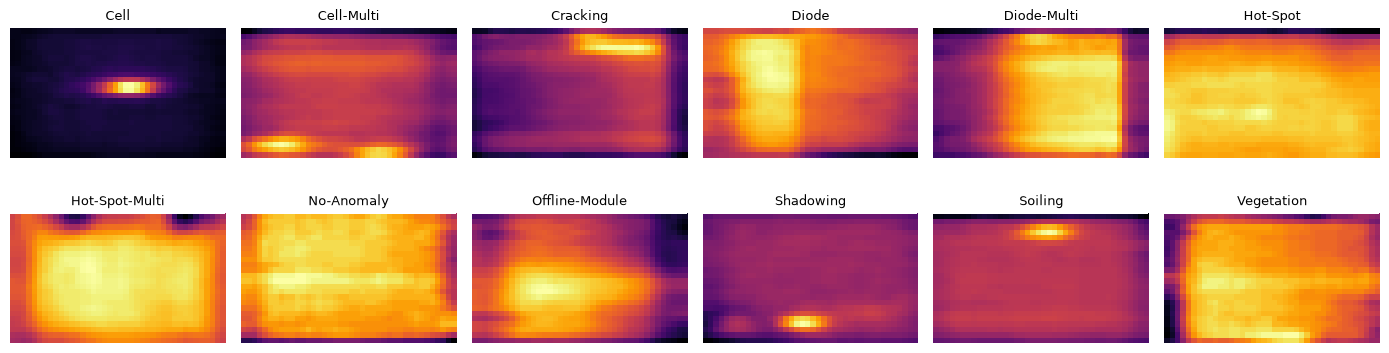

In [13]:
# 70% train / 15% val / 15% test (sinflar nisbati saqlanadi)
idx_all = np.arange(len(paths))
tr_idx, tmp_idx = train_test_split(idx_all, test_size=0.30, stratify=labels, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=labels[tmp_idx], random_state=SEED)
print("train/val/test:", len(tr_idx), len(va_idx), len(te_idx))

# Tasvirlarni ko'rib chiqamiz: har sinfdan bittadan, inferno rang xaritasi bilan
fig, axes = plt.subplots(2, 6, figsize=(14, 4.2))
for ax, ci in zip(axes.ravel(), range(len(class_names))):
    j = int(np.where(labels == ci)[0][0])
    ax.imshow(IMAGES[j], cmap="inferno")
    ax.set_title(class_names[ci], fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Dataset va augmentatsiya

In [14]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def to_rgb(im):
    # kulrang tasvirni 3 kanalga ko'paytiramiz (ImageNet modeli uchun)
    return im.convert("RGB")


# Issiqlik tasvirida rang/kontrast ma'noga ega — shuning uchun faqat yengil o'zgartirishlar
train_tfm = transforms.Compose([
    transforms.Resize((IMG_H, IMG_W), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomAffine(degrees=5, translate=(0.04, 0.04), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    to_rgb,
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tfm = transforms.Compose([
    transforms.Resize((IMG_H, IMG_W), interpolation=InterpolationMode.BICUBIC),
    to_rgb,
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


class IRDataset(Dataset):
    def __init__(self, idxs, tfm):
        self.idxs, self.tfm = idxs, tfm

    def __len__(self):
        return len(self.idxs)

    def __getitem__(self, i):
        j = self.idxs[i]
        return self.tfm(Image.fromarray(IMAGES[j])), int(labels[j])


pin = device.type == "cuda"
train_loader = DataLoader(IRDataset(tr_idx, train_tfm), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin, drop_last=True)
val_loader = DataLoader(IRDataset(va_idx, eval_tfm), batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(IRDataset(te_idx, eval_tfm), batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin)

## 4. Model

ImageNet'da o'qitilgan tayyor model (transfer learning) olinadi va oxirgi qatlami 12 sinfga almashtiriladi.

**Sinflar nomutanosib** (No-Anomaly = 10 000, Diode-Multi = 175), shuning uchun:
- yo'qotish funksiyasida sinf og'irliklari ishlatiladi (kvadrat ildiz bilan yumshatilgan),
- eng yaxshi epoxa **accuracy** emas, **macro-F1** bo'yicha tanlanadi.

In [15]:
def build_model(backbone, num_classes):
    if backbone == "efficientnet_b0":
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
    elif backbone == "mobilenet_v3_large":
        m = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.DEFAULT)
    else:
        raise ValueError(backbone)
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
    return m


model = build_model(BACKBONE, len(class_names)).to(device)

counts = np.bincount(labels[tr_idx], minlength=len(class_names))
cls_w = (counts.sum() / (len(counts) * np.maximum(counts, 1))) ** 0.5
criterion = nn.CrossEntropyLoss(weight=torch.tensor(cls_w, dtype=torch.float32, device=device),
                                label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(train_loader))
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
print("Parametrlar:", sum(p.numel() for p in model.parameters()) / 1e6, "M")

Parametrlar: 4.02292 M


## 5. O'qitish

In [16]:
@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    all_probs, all_y = [], []
    for x, y in loader:
        x = x.to(device)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(x)
        all_probs.append(F.softmax(logits.float(), dim=1).cpu().numpy())
        all_y.append(y.numpy())
    return np.concatenate(all_probs), np.concatenate(all_y)


history = {"train_loss": [], "val_macro_f1": [], "val_acc": []}
best_f1, best_state, bad_epochs = -1.0, None, 0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    running, seen = 0.0, 0
    for x, y in train_loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        running += loss.item() * x.size(0)
        seen += x.size(0)

    probs, y_val = predict_loader(model, val_loader)
    pred = probs.argmax(1)
    f1 = f1_score(y_val, pred, average="macro")
    acc = accuracy_score(y_val, pred)
    history["train_loss"].append(running / max(seen, 1))
    history["val_macro_f1"].append(f1)
    history["val_acc"].append(acc)
    print(f"Epoxa {epoch:02d}/{EPOCHS} | loss {running / max(seen, 1):.4f} | "
          f"val acc {acc:.4f} | val macro-F1 {f1:.4f} | {time.time() - t0:.0f}s")

    if f1 > best_f1:
        best_f1, bad_epochs = f1, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"Erta to'xtatildi: {PATIENCE} epoxa yaxshilanish yo'q.")
            break

model.load_state_dict(best_state)
print(f"Eng yaxshi val macro-F1: {best_f1:.4f}")

KeyboardInterrupt: 

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history["train_loss"]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoxa")
ax[1].plot(history["val_acc"], label="val accuracy")
ax[1].plot(history["val_macro_f1"], label="val macro-F1")
ax[1].set_title("Validatsiya"); ax[1].set_xlabel("epoxa"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Test to'plamida baholash

Model hech qachon ko'rmagan 15% tasvirda. Bundan tashqari **ikkilik** ko'rsatkichlar ham hisoblanadi:
"nosozlik bor / yo'q" — amalda eng muhimi **recall** (nosoz panelni o'tkazib yubormaslik).

In [ ]:
probs_te, y_te = predict_loader(model, test_loader)
pred_te = probs_te.argmax(1)

print(f"Test accuracy : {accuracy_score(y_te, pred_te):.4f}")
print(f"Test macro-F1 : {f1_score(y_te, pred_te, average='macro'):.4f}\n")
print(classification_report(y_te, pred_te, target_names=class_names, digits=3, zero_division=0))

# Ikkilik: anomaliya bormi?
y_bin = (y_te != NORMAL_IDX)
p_bin = (pred_te != NORMAL_IDX)
tp = int((y_bin & p_bin).sum()); fn = int((y_bin & ~p_bin).sum())
fp = int((~y_bin & p_bin).sum()); tn = int((~y_bin & ~p_bin).sum())
print(f"Anomaliya aniqlash — recall: {tp / max(tp + fn, 1):.3f} | precision: {tp / max(tp + fp, 1):.3f} "
      f"| o'tkazib yuborilgan: {fn} / {tp + fn}")

cm = confusion_matrix(y_te, pred_te, labels=range(len(class_names)))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names, fontsize=8)
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("Bashorat"); ax.set_ylabel("Haqiqiy"); ax.set_title("Confusion matrix (sonlar; rang = qator ulushi)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

## 7. Qizigan yuzani ko'rsatish

Ikki xil "issiq joy" hisoblanadi — ularni aralashtirmang:

| Usul | Nimani ko'rsatadi |
|---|---|
| **Grad-CAM** | Model **qaror qabul qilganda** tasvirning qaysi qismiga tayanganini. |
| **Issiq hudud maskasi** | Tasvirning **o'zida** yorqinligi o'rtachadan sezilarli yuqori joylar (`o'rtacha + k·σ`). Model kerak emas. |

`hot_area_percent` — modul yuzasining necha foizi "issiq hudud"ga tushgani. Bu **nisbiy** qiymat (°C emas).

In [ ]:
LABELS = {
    "Cell":           {"uz": "Bitta katakda qizish",            "ru": "Перегрев одной ячейки",              "en": "Single-cell hot spot"},
    "Cell-Multi":     {"uz": "Bir nechta katakda qizish",       "ru": "Перегрев нескольких ячеек",          "en": "Multi-cell hot spots"},
    "Cracking":       {"uz": "Yoriq",                           "ru": "Трещины",                            "en": "Cracking"},
    "Hot-Spot":       {"uz": "Issiq nuqta (yupqa plyonka)",     "ru": "Горячая точка (тонкоплёночная)",     "en": "Hot spot (thin film)"},
    "Hot-Spot-Multi": {"uz": "Bir nechta issiq nuqta",          "ru": "Несколько горячих точек",            "en": "Multiple hot spots"},
    "Shadowing":      {"uz": "Soya tushishi",                   "ru": "Затенение",                          "en": "Shadowing"},
    "Diode":          {"uz": "Faollashgan bypass diod",         "ru": "Сработавший байпас-диод",            "en": "Activated bypass diode"},
    "Diode-Multi":    {"uz": "Bir nechta bypass diod",          "ru": "Несколько байпас-диодов",            "en": "Multiple bypass diodes"},
    "Vegetation":     {"uz": "O'simlik to'sig'i",               "ru": "Заслонение растительностью",         "en": "Vegetation"},
    "Soiling":        {"uz": "Ifloslanish",                     "ru": "Загрязнение",                        "en": "Soiling"},
    "Offline-Module": {"uz": "O'chgan modul (butunlay qizigan)", "ru": "Отключённый модуль (перегрет целиком)", "en": "Offline module"},
    "No-Anomaly":     {"uz": "Nosozlik yo'q",                   "ru": "Без аномалий",                       "en": "No anomaly"},
}


class GradCAM:
    # Oxirgi konvolyutsiya qatlami bo'yicha Grad-CAM
    def __init__(self, model, layer):
        self.model, self.act, self.grad = model, None, None
        layer.register_forward_hook(self._fwd)

    def _fwd(self, module, inputs, output):
        self.act = output
        output.register_hook(lambda g: setattr(self, "grad", g))

    def __call__(self, x, class_idx=None):
        self.model.eval()
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = int(logits.argmax(1))
        logits[0, class_idx].backward()
        w = self.grad.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.act).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = cam.detach()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.cpu().numpy(), logits.detach()


gradcam = GradCAM(model, model.features[-1])


def hot_region_mask(gray_u8, k=1.5):
    # Tasvir ichida o'rtachadan k*sigma yuqori yorqinlikdagi hudud (nisbiy issiq joy)
    g = ndimage.gaussian_filter(gray_u8.astype(np.float32), sigma=0.6)
    mask = g > (g.mean() + k * g.std())
    mask = ndimage.binary_opening(mask, structure=np.ones((2, 2)))
    return mask


def analyze(pil_img, k=1.5):
    gray = pil_img.convert("L")
    gray_np = np.array(gray)
    x = eval_tfm(gray).unsqueeze(0).to(device)
    cam, logits = gradcam(x)
    probs = F.softmax(logits.float(), dim=1)[0].cpu().numpy()
    ci = int(probs.argmax())
    mask = hot_region_mask(gray_np, k)
    name = class_names[ci]
    return {
        "predicted_class": name,
        "label": LABELS.get(name, {}).get("uz", name),
        "confidence": float(probs[ci]),
        "is_anomaly": ci != NORMAL_IDX,
        "probabilities": {class_names[i]: float(probs[i]) for i in np.argsort(-probs)},
        "hot_area_percent": float(mask.mean() * 100),
        "gray": gray_np, "gradcam": cam, "hot_mask": mask,
    }


def show(result, title=None):
    gray = result["gray"].astype(np.float32)
    norm = (gray - gray.min()) / (gray.max() - gray.min() + 1e-8)
    cam = result["gradcam"]
    mask_up = np.array(Image.fromarray(result["hot_mask"].astype(np.uint8) * 255).resize(
        (cam.shape[1], cam.shape[0]), Image.NEAREST)) > 127
    base = np.array(Image.fromarray((norm * 255).astype(np.uint8)).resize((cam.shape[1], cam.shape[0]), Image.BICUBIC))

    fig, ax = plt.subplots(1, 4, figsize=(13, 2.6))
    ax[0].imshow(base, cmap="gray"); ax[0].set_title("Asl (kulrang)", fontsize=9)
    ax[1].imshow(base, cmap="inferno"); ax[1].set_title("Issiqlik (inferno)", fontsize=9)
    ax[2].imshow(base, cmap="gray"); ax[2].imshow(cam, cmap="jet", alpha=0.45)
    ax[2].set_title("Grad-CAM (model e'tibori)", fontsize=9)
    ax[3].imshow(base, cmap="gray"); ax[3].contour(mask_up, levels=[0.5], colors="red", linewidths=1.6)
    ax[3].set_title(f"Issiq hudud: {result['hot_area_percent']:.0f}%", fontsize=9)
    for a in ax:
        a.axis("off")
    verdict = "NOSOZLIK" if result["is_anomaly"] else "normal"
    fig.suptitle(f"{title + ' | ' if title else ''}{result['label']} — {result['confidence'] * 100:.1f}% ({verdict})",
                 fontsize=10, y=1.02)
    plt.tight_layout(); plt.show()


# Test to'plamidan har sinf uchun bittadan namuna
for ci, cname in enumerate(class_names):
    cand = [j for j in te_idx if labels[j] == ci]
    if not cand:
        continue
    j = cand[0]
    show(analyze(Image.fromarray(IMAGES[j])), title=f"haqiqiy: {cname}")

## 8. O'z rasmingizni sinash

Bitta **panel qirqimi** (yoki kulrang infraqizil tasvir) yuklang. Kichik/katta o'lcham muammo emas — avtomatik
o'zgartiriladi, lekin eng yaxshi natija dataset kabi (modul qirqimi) tasvirlarda bo'ladi.

In [ ]:
# [colab-only]
# DIQQAT: True bo'lsa, fayl tanlash oynasi ochiladi va siz fayl tanlamaguncha hujayra KUTIB TURADI.
# "Run all" paytida qotib qolmasligi uchun standart holatda o'chirilgan.
UPLOAD_OWN_IMAGE = False

if UPLOAD_OWN_IMAGE:
    try:
        from google.colab import files
        uploaded = files.upload()
        for fname, data in uploaded.items():
            res = analyze(Image.open(io.BytesIO(data)))
            show(res, title=fname)
            print({k: round(v, 3) for k, v in list(res["probabilities"].items())[:3]})
    except ImportError:
        print("Bu hujayra faqat Google Colab'da ishlaydi.")
else:
    print("O'tkazib yuborildi. O'z rasmingizni sinash uchun UPLOAD_OWN_IMAGE = True qiling va shu hujayrani ishga tushiring.")

## 9. Modelni saqlash

Saqlanadigan fayllar (keyin loyihadagi `model/` papkasiga qo'yiladi):

- `thermal_model.pt` — og'irliklar + sinf nomlari + sozlamalar,
- `thermal_class_names.json` — sinf nomlari,
- `thermal_labels.json` — UZ / RU / EN tarjimalar.

In [ ]:
ckpt = {
    "state_dict": best_state,
    "class_names": class_names,
    "backbone": BACKBONE,
    "img_size": (IMG_H, IMG_W),
    "mean": MEAN,
    "std": STD,
    "normal_class": "No-Anomaly",
    "val_macro_f1": float(best_f1),
}
torch.save(ckpt, os.path.join(SAVE_DIR, "thermal_model.pt"))
with open(os.path.join(SAVE_DIR, "thermal_class_names.json"), "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)
with open(os.path.join(SAVE_DIR, "thermal_labels.json"), "w", encoding="utf-8") as f:
    json.dump(LABELS, f, ensure_ascii=False, indent=2)

for fn in sorted(os.listdir(SAVE_DIR)):
    print(f"{fn:<28}{os.path.getsize(os.path.join(SAVE_DIR, fn)) / 1e6:6.1f} MB")

# Brauzer bir nechta faylni birdaniga yuklashni bloklashi mumkin — shuning uchun bitta zip qilamiz
import shutil
BUNDLE = shutil.make_archive("/content/thermal_model_bundle", "zip", SAVE_DIR)
print("\nZip tayyor:", BUNDLE, f"({os.path.getsize(BUNDLE) / 1e6:.1f} MB)")

### Yuklab olish — 3 ta yo'l (birortasi yetadi)

**A) Google Drive'ga saqlash (eng ishonchli).** Quyidagi hujayrani ishga tushiring, Google ruxsat so'raydi.
Fayllar Drive'dagi `solar_thermal` papkasiga tushadi.

**B) Brauzerga yuklab olish.** Keyingi hujayra `thermal_model_bundle.zip` ni yuklaydi. Agar hech narsa chiqmasa,
brauzer manzil satrida **"yuklab olish bloklandi"** belgisini bosib ruxsat bering va hujayrani qayta ishga tushiring.

**C) Qo'lda.** Chap tomondagi **papka belgisi (Files)** → `thermal_model_bundle.zip` → o'ng tomondagi **⋮ → Download**.

⚠️ Colab sessiyasi yopilsa, fayllar o'chadi. Shuning uchun yuklab olmasdan oynani yopmang.

In [ ]:
# [colab-only]  A) Google Drive'ga saqlash
from google.colab import drive
drive.mount("/content/drive")
dst = "/content/drive/MyDrive/solar_thermal"
os.makedirs(dst, exist_ok=True)
for fn in os.listdir(SAVE_DIR):
    shutil.copy(os.path.join(SAVE_DIR, fn), dst)
shutil.copy(BUNDLE, dst)
print("Drive'ga saqlandi:", dst, os.listdir(dst))

In [ ]:
# [colab-only]  B) Brauzerga yuklab olish (bitta zip fayl)
try:
    from google.colab import files
    files.download(BUNDLE)
except ImportError:
    print("Bu hujayra faqat Google Colab'da ishlaydi.")

## Keyingi qadam

`thermal_model.pt`, `thermal_class_names.json`, `thermal_labels.json` fayllarini loyihadagi `model/` papkasiga qo'ying.
Shundan so'ng veb-ilovaga **"Termal tahlil"** rejimini ulash mumkin (alohida endpoint + yuklash oynasi, natijada issiqlik xaritasi va issiq hudud foizi).